## Setup

In [ ]:
# Environment and path setup is handled in the next cell.


In [ ]:
import math
import sys
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Files available: {os.listdir(utils_path)}")

In [15]:
import matplotlib.pyplot as plt
from point_generator import *
from region_checks import *
from intersection_utils import *
from path_analysis import *
from plotting import *
from pruning import *
from filtered_paths import *
from utility_reset import *


In [16]:
# Reload modules to pick up fixes in intersection_utils.py and point_generator.py
import importlib
import intersection_utils
import point_generator
importlib.reload(intersection_utils)
importlib.reload(point_generator)
from intersection_utils import *
from point_generator import *
print("✓ Modules reloaded successfully!")

✓ Modules reloaded successfully!


---
## EXAMPLE 1: Two Simple Dangling Bonds (1 iteration needed)
A main percolating path with **2 simple dangling bonds**:
- Segment 5 connects to segment 0 (main path) but leads nowhere
- Segment 6 connects to segment 1 (main path) but leads nowhere

This requires **1 iteration** of pruning since both dangling bonds are directly connected to the main path.


EXAMPLE 1: TWO SIMPLE DANGLING BONDS
Intersections found: 6
Graph (segments at each node): [(1, 0), (1, 2), (1, 6), (3, 2), (3, 4), (5, 0)]

Boundary nodes:
  Source (x < 0.1): [0, 5]
    Node 0: (0.0500, 0.6000)
    Node 5: (0.0500, 0.4000)
  Drain (x > 0.9): [4]
    Node 4: (0.9200, 0.4000)
valor de queue antes = deque([0])
valor de queue depois = deque([])
nós visitados {0}
valor de target edge = (1, 0)
valor de path_pairs_of_lines = [(1, 0)]
valor do i = 1
valor do current node = 0
valor da queue após append = deque([1])
valor do path_pairs_of_nodes[0, 1]
valor do path_pairs_of_lines = [(1, 0), (1, 2)]
valor do path_pairs_of_edges = [(0, 1)]
valor do i = 2
valor do current node = 0
valor da queue após append = deque([1, 2])
valor do path_pairs_of_nodes[0, 1, 2]
valor do path_pairs_of_lines = [(1, 0), (1, 2), (1, 6)]
valor do path_pairs_of_edges = [(0, 1), (0, 2)]
valor do i = 5
valor do current node = 0
valor da queue após append = deque([1, 2, 5])
valor do path_pairs_of_nodes[0, 

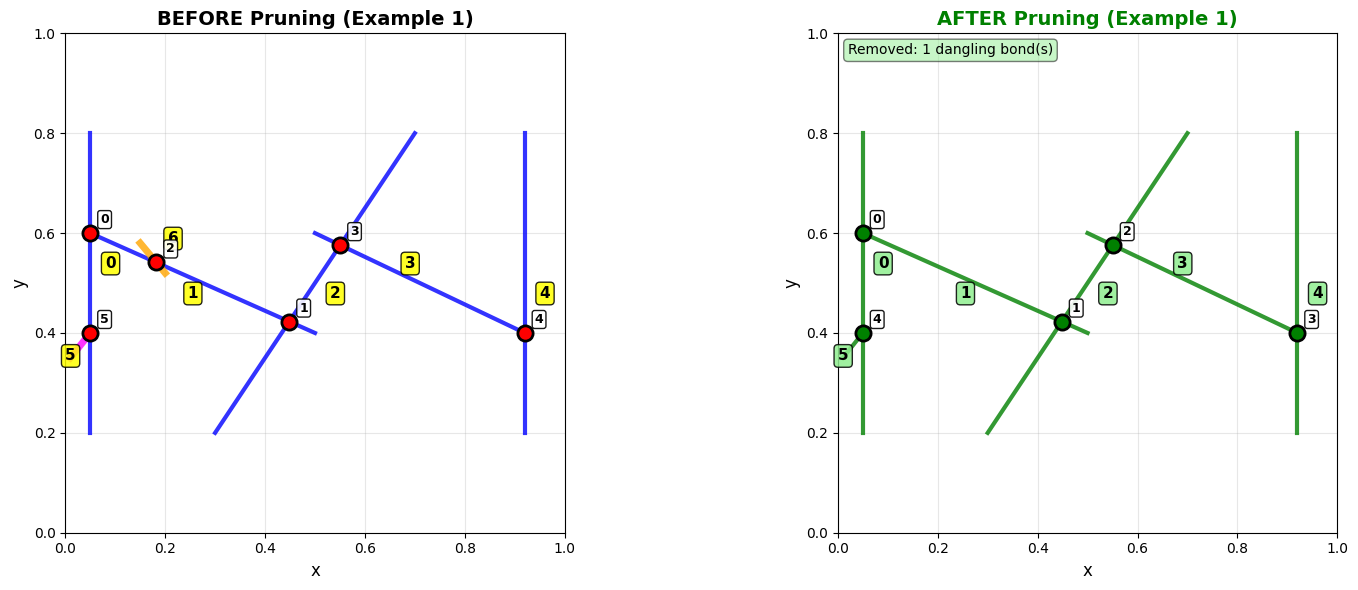

In [ ]:
# EXAMPLE 1: Network with TWO simple dangling bonds
print("\n" + "="*70)
print("EXAMPLE 1: TWO SIMPLE DANGLING BONDS")
print("="*70)

N_ex1 = 7  # 5 main percolating segments + 2 dangling

# Main percolating path (segments 0-4): Based on working test_simple_percolation.ipynb
# Dangling bonds (segments 5-6): Two dead ends that should be removed
points_1_ex1 = [
    # ===== Main percolating path (0-4) =====
    [0.05, 0.20],   # Segment 0: vertical at source
    [0.05, 0.60],   # Segment 1: diagonal from source through middle
    [0.30, 0.20],   # Segment 2: diagonal crossing middle
    [0.50, 0.60],   # Segment 3: diagonal to drain
    [0.92, 0.20],   # Segment 4: vertical at drain
    # ===== TWO Dangling bonds - connected but dead ends =====
    [0.05, 0.40],   # Segment 5: branches from segment 0
    [0.20, 0.52],   # Segment 6: branches from segment 1
]

points_2_ex1 = [
    # ===== Main percolating path (0-4) =====
    [0.05, 0.80],   # Segment 0
    [0.50, 0.40],   # Segment 1
    [0.70, 0.80],   # Segment 2
    [0.92, 0.40],   # Segment 3
    [0.92, 0.80],   # Segment 4
    # ===== TWO Dangling bonds - dead ends pointing away =====
    [0.01, 0.35],   # Segment 5: DEAD END (left from segment 0)
    [0.15, 0.58],   # Segment 6: DEAD END (away from segment 1)
]

# Calculate angles using the new calculate_angles function
angles_ex1 = calculate_angles(points_1_ex1, points_2_ex1)

# Find intersections
intersections_ex1 = []
intersected_line_1_ex1 = []
intersected_line_2_ex1 = []
graph_ex1 = []

intersections_ex1, intersected_line_1_ex1, intersected_line_2_ex1, graph_ex1 = identify_intersections(
    points_1_ex1, points_2_ex1, intersections_ex1, intersected_line_1_ex1,
    intersected_line_2_ex1, graph_ex1, angles_ex1, 0.7, N_ex1
)

print(f"Intersections found: {len(intersections_ex1)}")
print(f"Graph (segments at each node): {graph_ex1}")

# Find boundary nodes
boundary_source_ex1 = []
boundary_drain_ex1 = []
for i in range(len(intersections_ex1)):
    if intersections_ex1[i][0] < 0.1:
        boundary_source_ex1.append(i)
    elif intersections_ex1[i][0] > 0.9:
        boundary_drain_ex1.append(i)

if not boundary_source_ex1 or not boundary_drain_ex1:
    raise ValueError(
        f"Example 1 strict boundary failed: source={len(boundary_source_ex1)}, drain={len(boundary_drain_ex1)}. No fallback allowed."
    )

# Print boundary nodes with coordinates
print("\nBoundary nodes:")
print(f"  Source (x < 0.1): {boundary_source_ex1}")
for node in boundary_source_ex1:
    print(f"    Node {node}: ({intersections_ex1[node][0]:.4f}, {intersections_ex1[node][1]:.4f})")
print(f"  Drain (x > 0.9): {boundary_drain_ex1}")
for node in boundary_drain_ex1:
    print(f"    Node {node}: ({intersections_ex1[node][0]:.4f}, {intersections_ex1[node][1]:.4f})")

# Find paths before pruning
path_nodes_ex1 = []
path_pairs_of_lines_ex1 = []
path_pairs_of_edges_ex1 = []
all_path_perc_ex1 = []
all_path_nodes_ex1 = []

for i in boundary_source_ex1:
    do_not_check = 0
    for k in range(len(all_path_nodes_ex1)):
        if i in all_path_nodes_ex1[k]:
            do_not_check = 1
            break
    if do_not_check == 0:
        nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
            intersections_ex1, graph_ex1, i
        )
        path_nodes_ex1.append(nodes)
        path_pairs_of_lines_ex1.append(pair_of_lines)
        path_pairs_of_edges_ex1.append(pair_of_edges)
        all_path_perc_ex1.append(path_perc)
        all_path_nodes_ex1.append(nodes)

print(f"Boundary nodes -> source: {boundary_source_ex1}, drain: {boundary_drain_ex1}")
print(f"Paths found: {len(path_nodes_ex1)}, Percolating: {sum(1 for p in all_path_perc_ex1 if p == 1)}")

# Identify segments in percolating paths
segments_in_perc_ex1 = set()
for i, perc in enumerate(all_path_perc_ex1):
    if perc == 1:
        for edge_pair in path_pairs_of_lines_ex1[i]:
            segments_in_perc_ex1.update(edge_pair)
print(f"Segments in percolating paths: {sorted(segments_in_perc_ex1)}")

# Get boundary segments
source_segments_ex1 = set()
drain_segments_ex1 = set()
for node_idx in boundary_source_ex1:
    if node_idx < len(graph_ex1):
        source_segments_ex1.update(graph_ex1[node_idx])
for node_idx in boundary_drain_ex1:
    if node_idx < len(graph_ex1):
        drain_segments_ex1.update(graph_ex1[node_idx])

# ═══════════════════════════════════════════════════════════════════════
# 🔧 APPLYING PRUNING ALGORITHM - prune_dangling_bonds() from pruning.py
# ═══════════════════════════════════════════════════════════════════════
print("\n" + "="*70)
print(">>> CALLING: prune_dangling_bonds() FROM pruning.py (EXAMPLE 1)")
print("="*70)

# Apply pruning
filtered_pair_of_lines_ex1, filtered_path_nodes_ex1, filtered_pair_of_edges_ex1 = prune_dangling_bonds(
    path_pairs_of_lines_ex1, path_nodes_ex1, path_pairs_of_edges_ex1,
    source_segments_ex1, drain_segments_ex1
)

print("="*70)
print(">>> PRUNING COMPLETED (EXAMPLE 1)")
print("="*70)

# Extract remaining segments
segments_after_ex1 = set()
for path in filtered_pair_of_lines_ex1:
    for edge_pair in path:
        segments_after_ex1.update(edge_pair)
segments_after_ex1 = sorted(list(segments_after_ex1))
segments_removed_ex1 = [i for i in range(N_ex1) if i not in segments_after_ex1]

print(f"\nAfter pruning:")
print(f"  Remaining segments: {segments_after_ex1}")
print(f"  Removed segments: {segments_removed_ex1}")
print(f"  Expected: Remove segments 5-6 (the two dangling bonds)")

# Create pruned network
points_1_pruned_ex1 = [points_1_ex1[i] for i in segments_after_ex1]
points_2_pruned_ex1 = [points_2_ex1[i] for i in segments_after_ex1]
N_pruned_ex1 = len(segments_after_ex1)

# Re-analyze pruned network
intersections_pruned_ex1 = []
intersected_line_1_pruned_ex1 = []
intersected_line_2_pruned_ex1 = []
graph_pruned_ex1 = []

if N_pruned_ex1 > 0:
    angles_pruned_ex1 = [angles_ex1[i] for i in segments_after_ex1]
    intersections_pruned_ex1, intersected_line_1_pruned_ex1, intersected_line_2_pruned_ex1, graph_pruned_ex1 = identify_intersections(
        points_1_pruned_ex1, points_2_pruned_ex1, intersections_pruned_ex1,
        intersected_line_1_pruned_ex1, intersected_line_2_pruned_ex1, graph_pruned_ex1,
        angles_pruned_ex1, 0.7, N_pruned_ex1
    )

print(f"Intersections after pruning: {len(intersections_pruned_ex1)}")

# Visualize
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Before pruning
for i in range(N_ex1):
    color = 'blue' if i in segments_in_perc_ex1 else 'red'
    linewidth = 3 if i in segments_in_perc_ex1 else 2
    if i == 5:
        color = 'magenta'
        linewidth = 5
    if i == 6:
        color = 'orange'
        linewidth = 5
    ax1.plot([points_1_ex1[i][0], points_2_ex1[i][0]],
             [points_1_ex1[i][1], points_2_ex1[i][1]],
             linestyle='-', color=color, linewidth=linewidth, alpha=0.8)
    mid_x = (points_1_ex1[i][0] + points_2_ex1[i][0]) / 2
    mid_y = (points_1_ex1[i][1] + points_2_ex1[i][1]) / 2
    offset_x = 0.03 if i % 2 == 0 else -0.03
    offset_y = 0.03 if i % 3 == 0 else -0.03
    ax1.text(mid_x + offset_x, mid_y + offset_y, str(i), fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='yellow', alpha=0.85))

# Plot intersections with node IDs
if len(intersections_ex1) > 0:
    for node_id, (x, y) in enumerate(intersections_ex1):
        ax1.scatter(x, y, c='red', marker='o', s=120, zorder=5, edgecolors='black', linewidths=2)
        ax1.text(x + 0.02, y + 0.02, str(node_id), fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

ax1.set_title("BEFORE Pruning (Example 1)", fontsize=14, fontweight='bold')
ax1.set_xlabel("x", fontsize=12)
ax1.set_ylabel("y", fontsize=12)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.set_aspect('equal')
ax1.grid(True, alpha=0.3)

# After pruning
for i, orig_idx in enumerate(segments_after_ex1):
    ax2.plot([points_1_pruned_ex1[i][0], points_2_pruned_ex1[i][0]],
             [points_1_pruned_ex1[i][1], points_2_pruned_ex1[i][1]],
             linestyle='-', color='green', linewidth=3, alpha=0.8)
    mid_x = (points_1_pruned_ex1[i][0] + points_2_pruned_ex1[i][0]) / 2
    mid_y = (points_1_pruned_ex1[i][1] + points_2_pruned_ex1[i][1]) / 2
    offset_x = 0.03 if i % 2 == 0 else -0.03
    offset_y = 0.03 if i % 3 == 0 else -0.03
    ax2.text(mid_x + offset_x, mid_y + offset_y, str(orig_idx), fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='lightgreen', alpha=0.85))

# Plot intersections with node IDs
if len(intersections_pruned_ex1) > 0:
    for node_id, (x, y) in enumerate(intersections_pruned_ex1):
        ax2.scatter(x, y, c='green', marker='o', s=120, zorder=5, edgecolors='black', linewidths=2)
        ax2.text(x + 0.02, y + 0.02, str(node_id), fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

ax2.set_title("AFTER Pruning (Example 1)", fontsize=14, fontweight='bold', color='green')
ax2.set_xlabel("x", fontsize=12)
ax2.set_ylabel("y", fontsize=12)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.3)
ax2.text(0.02, 0.98, f'Removed: {len(segments_removed_ex1)} dangling bond(s)',
         transform=ax2.transAxes, fontsize=10, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

plt.tight_layout()
plt.show()

print("="*70)


---
## EXAMPLE 2: Two Dangling Bonds with Wave Pattern (1 iteration needed)
A main percolating path with **2 simple dangling bonds** (different geometry):
- Segment 5 connects to segment 1 (main path) but leads nowhere
- Segment 6 connects to segment 4 (main path) but leads nowhere

This requires **1 iteration** of pruning since both dangling bonds are directly connected to the main path.


EXAMPLE 2: TWO DANGLING BONDS
Intersections found: 6
Graph (segments at each node): [(1, 0), (1, 2), (1, 5), (3, 2), (3, 4), (6, 4)]

Boundary nodes:
  Source (x < 0.1): [0]
    Node 0: (0.2066, 0.5759)
  Drain (x > 0.9): [4]
    Node 4: (0.7977, 0.5041)
valor de queue antes = deque([0])
valor de queue depois = deque([])
nós visitados {0}
valor de target edge = (1, 0)
valor de path_pairs_of_lines = [(1, 0)]
valor do i = 1
valor do current node = 0
valor da queue após append = deque([1])
valor do path_pairs_of_nodes[0, 1]
valor do path_pairs_of_lines = [(1, 0), (1, 2)]
valor do path_pairs_of_edges = [(0, 1)]
valor do i = 2
valor do current node = 0
valor da queue após append = deque([1, 2])
valor do path_pairs_of_nodes[0, 1, 2]
valor do path_pairs_of_lines = [(1, 0), (1, 2), (1, 5)]
valor do path_pairs_of_edges = [(0, 1), (0, 2)]
valor de queue antes = deque([1, 2])
valor de queue depois = deque([2])
nós visitados {0, 1}
valor de target edge = (1, 2)
valor do i = 3
valor do current nod

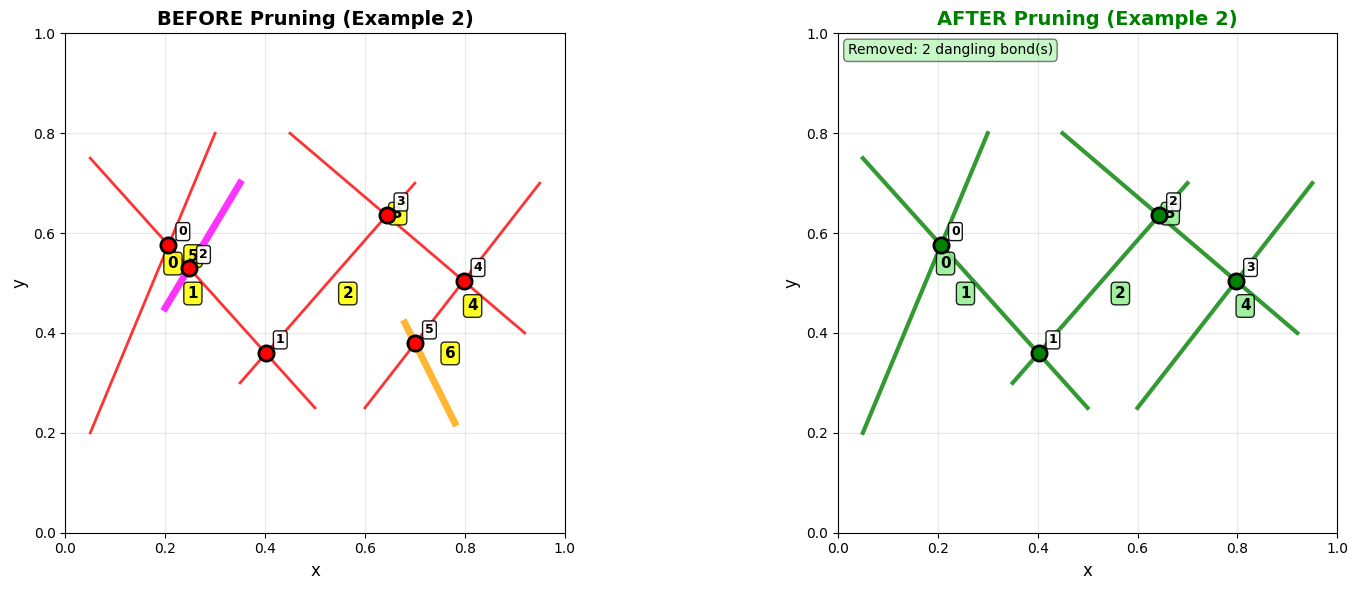

In [ ]:
# EXAMPLE 2: Network with TWO dangling bonds (crossing wave pattern)
print("\n" + "="*70)
print("EXAMPLE 2: TWO DANGLING BONDS")
print("="*70)

N_ex2 = 7  # 5 main percolating segments + 2 dangling

# CROSSING WAVE: Main segments cross each other to ensure intersections and percolation
# Different from Example 1's vertical-diagonal pattern
points_1_ex2 = [
    # Main percolating path (segments 0-4)
    [0.05, 0.20],   # Segment 0: source to upper middle
    [0.05, 0.75],   # Segment 1: source to lower middle (crosses seg 0)
    [0.35, 0.30],   # Segment 2: middle lower to upper right
    [0.45, 0.80],   # Segment 3: middle upper to drain side
    [0.60, 0.25],   # Segment 4: middle right to drain
    # Two dangling bonds (segments 5-6) - TRUE DEAD ENDS (only one intersection each)
    [0.20, 0.45],   # Segment 5: DANGLING - crosses segment 1, goes nowhere
    [0.68, 0.42],   # Segment 6: DANGLING - crosses segment 4 in the middle (not at drain)
]

points_2_ex2 = [
    # Main percolating path (segments 0-4)
    [0.30, 0.80],   # Segment 0: crosses segment 1, 2
    [0.50, 0.25],   # Segment 1: crosses segment 0, 2, 3
    [0.70, 0.70],   # Segment 2: crosses segment 0, 1, 3, 4
    [0.92, 0.40],   # Segment 3: crosses segment 1, 2, 4 (reaches drain side)
    [0.95, 0.70],   # Segment 4: reaches drain (crosses segment 2, 3)
    # Two dangling bonds - dead ends (extend away from other segments)
    [0.35, 0.70],   # Segment 5: DEAD END (crosses segment 1, then goes nowhere)
    [0.78, 0.22],   # Segment 6: DEAD END (goes down and away, no other crossings)
]

# Calculate angles using the new calculate_angles function
angles_ex2 = calculate_angles(points_1_ex2, points_2_ex2)

# Find intersections
intersections_ex2 = []
intersected_line_1_ex2 = []
intersected_line_2_ex2 = []
graph_ex2 = []

intersections_ex2, intersected_line_1_ex2, intersected_line_2_ex2, graph_ex2 = identify_intersections(
    points_1_ex2, points_2_ex2, intersections_ex2, intersected_line_1_ex2,
    intersected_line_2_ex2, graph_ex2, angles_ex2, 0.7, N_ex2
)

print(f"Intersections found: {len(intersections_ex2)}")
print(f"Graph (segments at each node): {graph_ex2}")

# Find boundary nodes (primary rule: strict bands near 0 and 1)
boundary_source_ex2 = []
boundary_drain_ex2 = []
for i in range(len(intersections_ex2)):
    if intersections_ex2[i][0] < 0.1:
        boundary_source_ex2.append(i)
    elif intersections_ex2[i][0] > 0.9:
        boundary_drain_ex2.append(i)

if not boundary_source_ex2 or not boundary_drain_ex2:
    raise ValueError(
        f"Example 2 strict boundary failed: source={len(boundary_source_ex2)}, drain={len(boundary_drain_ex2)}. No fallback allowed."
    )

# Print boundary nodes with coordinates
print("\nBoundary nodes:")
print(f"  Source (x < 0.1): {boundary_source_ex2}")
for node in boundary_source_ex2:
    print(f"    Node {node}: ({intersections_ex2[node][0]:.4f}, {intersections_ex2[node][1]:.4f})")
print(f"  Drain (x > 0.9): {boundary_drain_ex2}")
for node in boundary_drain_ex2:
    print(f"    Node {node}: ({intersections_ex2[node][0]:.4f}, {intersections_ex2[node][1]:.4f})")

# Find paths before pruning
path_nodes_ex2 = []
path_pairs_of_lines_ex2 = []
path_pairs_of_edges_ex2 = []
all_path_perc_ex2 = []
all_path_nodes_ex2 = []

for i in boundary_source_ex2:
    do_not_check = 0
    for k in range(len(all_path_nodes_ex2)):
        if i in all_path_nodes_ex2[k]:
            do_not_check = 1
            break
    if do_not_check == 0:
        nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
            intersections_ex2, graph_ex2, i
        )
        path_nodes_ex2.append(nodes)
        path_pairs_of_lines_ex2.append(pair_of_lines)
        path_pairs_of_edges_ex2.append(pair_of_edges)
        all_path_perc_ex2.append(path_perc)
        all_path_nodes_ex2.append(nodes)

print(f"Boundary nodes -> source: {boundary_source_ex2}, drain: {boundary_drain_ex2}")
print(f"Paths found: {len(path_nodes_ex2)}, Percolating: {sum(1 for p in all_path_perc_ex2 if p == 1)}")

# Identify segments in percolating paths
segments_in_perc_ex2 = set()
for i, perc in enumerate(all_path_perc_ex2):
    if perc == 1:
        for edge_pair in path_pairs_of_lines_ex2[i]:
            segments_in_perc_ex2.update(edge_pair)
print(f"Segments in percolating paths: {sorted(segments_in_perc_ex2)}")

# Get boundary segments
source_segments_ex2 = set()
drain_segments_ex2 = set()
for node_idx in boundary_source_ex2:
    if node_idx < len(graph_ex2):
        source_segments_ex2.update(graph_ex2[node_idx])
for node_idx in boundary_drain_ex2:
    if node_idx < len(graph_ex2):
        drain_segments_ex2.update(graph_ex2[node_idx])

# ═══════════════════════════════════════════════════════════════════════
# 🔧 APPLYING PRUNING ALGORITHM - prune_dangling_bonds() from pruning.py
# ═══════════════════════════════════════════════════════════════════════
print("\n" + "="*70)
print(">>> CALLING: prune_dangling_bonds() FROM pruning.py (EXAMPLE 2)")
print("="*70)

# Apply pruning
filtered_pair_of_lines_ex2, filtered_path_nodes_ex2, filtered_pair_of_edges_ex2 = prune_dangling_bonds(
    path_pairs_of_lines_ex2, path_nodes_ex2, path_pairs_of_edges_ex2,
    source_segments_ex2, drain_segments_ex2
)

print("="*70)
print(">>> PRUNING COMPLETED (EXAMPLE 2)")
print("="*70)

# Extract remaining segments
segments_after_ex2 = set()
for path in filtered_pair_of_lines_ex2:
    for edge_pair in path:
        segments_after_ex2.update(edge_pair)
segments_after_ex2 = sorted(list(segments_after_ex2))
segments_removed_ex2 = [i for i in range(N_ex2) if i not in segments_after_ex2]

print(f"\nAfter pruning:")
print(f"  Remaining segments: {segments_after_ex2}")
print(f"  Removed segments: {segments_removed_ex2}")
print(f"  Expected: Remove segments 5-6 (the two dangling bonds)")

# Create pruned network
points_1_pruned_ex2 = [points_1_ex2[i] for i in segments_after_ex2]
points_2_pruned_ex2 = [points_2_ex2[i] for i in segments_after_ex2]
N_pruned_ex2 = len(segments_after_ex2)

# Re-analyze pruned network
intersections_pruned_ex2 = []
intersected_line_1_pruned_ex2 = []
intersected_line_2_pruned_ex2 = []
graph_pruned_ex2 = []

if N_pruned_ex2 > 0:
    angles_pruned_ex2 = [angles_ex2[i] for i in segments_after_ex2]
    intersections_pruned_ex2, intersected_line_1_pruned_ex2, intersected_line_2_pruned_ex2, graph_pruned_ex2 = identify_intersections(
        points_1_pruned_ex2, points_2_pruned_ex2, intersections_pruned_ex2,
        intersected_line_1_pruned_ex2, intersected_line_2_pruned_ex2, graph_pruned_ex2,
        angles_pruned_ex2, 0.7, N_pruned_ex2
    )

print(f"Intersections after pruning: {len(intersections_pruned_ex2)}")

# Visualize
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Before pruning
for i in range(N_ex2):
    color = 'blue' if i in segments_in_perc_ex2 else 'red'
    linewidth = 3 if i in segments_in_perc_ex2 else 2
    if i == 5:
        color = 'magenta'
        linewidth = 5
    if i == 6:
        color = 'orange'
        linewidth = 5
    ax1.plot([points_1_ex2[i][0], points_2_ex2[i][0]],
             [points_1_ex2[i][1], points_2_ex2[i][1]],
             linestyle='-', color=color, linewidth=linewidth, alpha=0.8)
    # Add segment labels with slight offset to avoid overlap
    mid_x = (points_1_ex2[i][0] + points_2_ex2[i][0]) / 2
    mid_y = (points_1_ex2[i][1] + points_2_ex2[i][1]) / 2
    offset_x = 0.03 if i % 2 == 0 else -0.03
    offset_y = 0.03 if i % 3 == 0 else -0.03
    ax1.text(mid_x + offset_x, mid_y + offset_y, str(i), fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='yellow', alpha=0.85))

# Plot intersections with node IDs
if len(intersections_ex2) > 0:
    for node_id, (x, y) in enumerate(intersections_ex2):
        ax1.scatter(x, y, c='red', marker='o', s=120, zorder=5, edgecolors='black', linewidths=2)
        ax1.text(x + 0.02, y + 0.02, str(node_id), fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

ax1.set_title("BEFORE Pruning (Example 2)", fontsize=14, fontweight='bold')
ax1.set_xlabel("x", fontsize=12)
ax1.set_ylabel("y", fontsize=12)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.set_aspect('equal')
ax1.grid(True, alpha=0.3)

# After pruning
for i, orig_idx in enumerate(segments_after_ex2):
    ax2.plot([points_1_pruned_ex2[i][0], points_2_pruned_ex2[i][0]],
             [points_1_pruned_ex2[i][1], points_2_pruned_ex2[i][1]],
             linestyle='-', color='green', linewidth=3, alpha=0.8)
    # Label with original segment ID with offset
    mid_x = (points_1_pruned_ex2[i][0] + points_2_pruned_ex2[i][0]) / 2
    mid_y = (points_1_pruned_ex2[i][1] + points_2_pruned_ex2[i][1]) / 2
    offset_x = 0.03 if i % 2 == 0 else -0.03
    offset_y = 0.03 if i % 3 == 0 else -0.03
    ax2.text(mid_x + offset_x, mid_y + offset_y, str(orig_idx), fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='lightgreen', alpha=0.85))

# Plot intersections with node IDs
if len(intersections_pruned_ex2) > 0:
    for node_id, (x, y) in enumerate(intersections_pruned_ex2):
        ax2.scatter(x, y, c='green', marker='o', s=120, zorder=5, edgecolors='black', linewidths=2)
        ax2.text(x + 0.02, y + 0.02, str(node_id), fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

ax2.set_title("AFTER Pruning (Example 2)", fontsize=14, fontweight='bold', color='green')
ax2.set_xlabel("x", fontsize=12)
ax2.set_ylabel("y", fontsize=12)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.3)
ax2.text(0.02, 0.98, f'Removed: {len(segments_removed_ex2)} dangling bond(s)',
         transform=ax2.transAxes, fontsize=10, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

plt.tight_layout()
plt.show()

print("="*70)

---
## EXAMPLE 3: Chained Dangling Bonds (2 iterations needed)
A main percolating path with a **chain of 2 dangling bonds**:
- Segment 5 connects to the main path (segment 1)
- Segment 6 connects ONLY to segment 5 (not to the main path)

This requires **2 iterations** of pruning:
1. First iteration: Remove segment 6 (only has 1 connection to segment 5)
2. Second iteration: Remove segment 5 (now only has 1 connection after segment 6 was removed)


EXAMPLE 3: CHAINED DANGLING BONDS (2 ITERATIONS)
Intersections found: 6
Graph (segments at each node): [(1, 0), (1, 2), (1, 5), (3, 2), (3, 4), (6, 5)]

Verifying segment connections:
  Segment 0 connects to: [1]
  Segment 1 connects to: [0, 2, 5]
  Segment 2 connects to: [1, 3]
  Segment 3 connects to: [2, 4]
  Segment 4 connects to: [3]
  Segment 5 connects to: [1, 6]
  Segment 6 connects to: [5]

Boundary nodes:
  Source (x < 0.1): [0]
    Node 0: (0.0500, 0.6000)
  Drain (x > 0.9): [4]
    Node 4: (0.9200, 0.4000)
valor de queue antes = deque([0])
valor de queue depois = deque([])
nós visitados {0}
valor de target edge = (1, 0)
valor de path_pairs_of_lines = [(1, 0)]
valor do i = 1
valor do current node = 0
valor da queue após append = deque([1])
valor do path_pairs_of_nodes[0, 1]
valor do path_pairs_of_lines = [(1, 0), (1, 2)]
valor do path_pairs_of_edges = [(0, 1)]
valor do i = 2
valor do current node = 0
valor da queue após append = deque([1, 2])
valor do path_pairs_of_nodes[0,

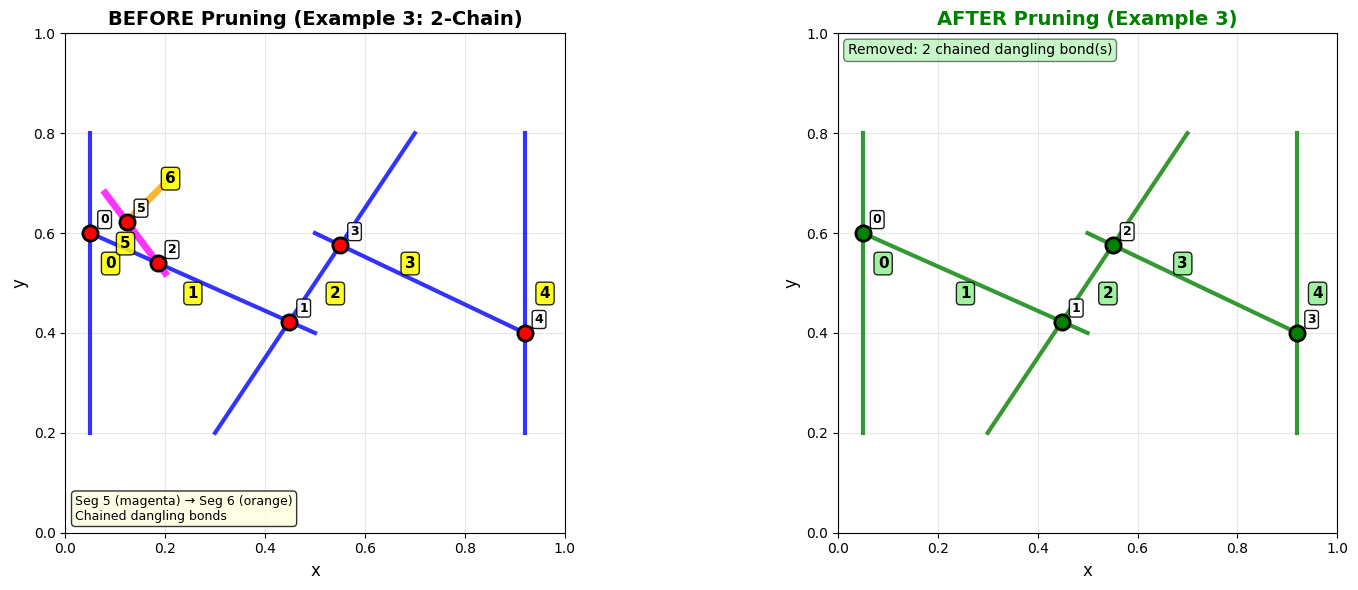

In [ ]:
# EXAMPLE 3: Chained Dangling Bonds (2 iterations needed)
# Uses the SAME PROVEN main path from Example 1, but with a CHAIN of 2 dangling bonds
print("\n" + "="*70)
print("EXAMPLE 3: CHAINED DANGLING BONDS (2 ITERATIONS)")
print("="*70)

N_ex3 = 7  # 5 main path segments + 2 chained dangling

# USING PROVEN GEOMETRY FROM EXAMPLE 1 for the main path!
# Main path: segments 0-4 (identical to Example 1)
# Dangling chain: segment 5 branches off segment 1, segment 6 branches off segment 5

points_1_ex3 = [
    # ===== Main percolating path (0-4) - COPIED FROM EXAMPLE 1 =====
    [0.05, 0.20],   # Segment 0: vertical at source
    [0.05, 0.60],   # Segment 1: diagonal from source through middle
    [0.30, 0.20],   # Segment 2: diagonal crossing middle
    [0.50, 0.60],   # Segment 3: diagonal to drain
    [0.92, 0.20],   # Segment 4: vertical at drain
    # ===== CHAINED Dangling bonds (2 connected) =====
    [0.20, 0.52],   # Segment 5: branches from segment 1 (same start as Ex1 seg 6)
    [0.12, 0.62],   # Segment 6: branches from segment 5 ONLY (forms chain)
]

points_2_ex3 = [
    # ===== Main percolating path (0-4) - COPIED FROM EXAMPLE 1 =====
    [0.05, 0.80],   # Segment 0
    [0.50, 0.40],   # Segment 1
    [0.70, 0.80],   # Segment 2
    [0.92, 0.40],   # Segment 3
    [0.92, 0.80],   # Segment 4
    # ===== CHAINED Dangling bonds =====
    [0.08, 0.68],   # Segment 5: goes up-left, crosses seg 1 AND seg 6
    [0.22, 0.72],   # Segment 6: goes right, ONLY crosses seg 5 (dead end)
]

# Calculate angles using the new calculate_angles function
angles_ex3 = calculate_angles(points_1_ex3, points_2_ex3)

# Find intersections
intersections_ex3 = []
intersected_line_1_ex3 = []
intersected_line_2_ex3 = []
graph_ex3 = []

intersections_ex3, intersected_line_1_ex3, intersected_line_2_ex3, graph_ex3 = identify_intersections(
    points_1_ex3, points_2_ex3, intersections_ex3, intersected_line_1_ex3,
    intersected_line_2_ex3, graph_ex3, angles_ex3, 0.7, N_ex3
)

print(f"Intersections found: {len(intersections_ex3)}")
print(f"Graph (segments at each node): {graph_ex3}")

# Verify the chain structure
print("\nVerifying segment connections:")
seg_connections = {}
for segs in graph_ex3:
    for s in segs:
        if s not in seg_connections:
            seg_connections[s] = set()
        for other in segs:
            if other != s:
                seg_connections[s].add(other)
for seg_id in sorted(seg_connections.keys()):
    print(f"  Segment {seg_id} connects to: {sorted(seg_connections[seg_id])}")

# Find boundary nodes
boundary_source_ex3 = []
boundary_drain_ex3 = []
for i in range(len(intersections_ex3)):
    if intersections_ex3[i][0] < 0.1:
        boundary_source_ex3.append(i)
    elif intersections_ex3[i][0] > 0.9:
        boundary_drain_ex3.append(i)

if not boundary_source_ex3 or not boundary_drain_ex3:
    raise ValueError(
        f"Example 3 strict boundary failed: source={len(boundary_source_ex3)}, drain={len(boundary_drain_ex3)}. No fallback allowed."
    )

# Print boundary nodes with coordinates
print("\nBoundary nodes:")
print(f"  Source (x < 0.1): {boundary_source_ex3}")
for node in boundary_source_ex3:
    print(f"    Node {node}: ({intersections_ex3[node][0]:.4f}, {intersections_ex3[node][1]:.4f})")
print(f"  Drain (x > 0.9): {boundary_drain_ex3}")
for node in boundary_drain_ex3:
    print(f"    Node {node}: ({intersections_ex3[node][0]:.4f}, {intersections_ex3[node][1]:.4f})")

# Find paths before pruning
path_nodes_ex3 = []
path_pairs_of_lines_ex3 = []
path_pairs_of_edges_ex3 = []
all_path_perc_ex3 = []
all_path_nodes_ex3 = []

for i in boundary_source_ex3:
    do_not_check = 0
    for k in range(len(all_path_nodes_ex3)):
        if i in all_path_nodes_ex3[k]:
            do_not_check = 1
            break
    if do_not_check == 0:
        nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
            intersections_ex3, graph_ex3, i
        )
        path_nodes_ex3.append(nodes)
        path_pairs_of_lines_ex3.append(pair_of_lines)
        path_pairs_of_edges_ex3.append(pair_of_edges)
        all_path_perc_ex3.append(path_perc)
        all_path_nodes_ex3.append(nodes)

print(f"\nBoundary nodes -> source: {boundary_source_ex3}, drain: {boundary_drain_ex3}")
print(f"Paths found: {len(path_nodes_ex3)}, Percolating: {sum(1 for p in all_path_perc_ex3 if p == 1)}")

# Get boundary segments
source_segments_ex3 = set()
drain_segments_ex3 = set()
for node_idx in boundary_source_ex3:
    if node_idx < len(graph_ex3):
        source_segments_ex3.update(graph_ex3[node_idx])
for node_idx in boundary_drain_ex3:
    if node_idx < len(graph_ex3):
        drain_segments_ex3.update(graph_ex3[node_idx])

print(f"Source segments: {source_segments_ex3}, Drain segments: {drain_segments_ex3}")

# ═══════════════════════════════════════════════════════════════════════
# 🔧 APPLYING PRUNING ALGORITHM - should take 2 iterations
# ═══════════════════════════════════════════════════════════════════════
print("\n" + "="*70)
print(">>> CALLING: prune_dangling_bonds() FROM pruning.py (EXAMPLE 3)")
print(">>> EXPECTING 2 ITERATIONS:")
print(">>>   Iteration 1: Remove segment 6 (only connected to seg 5)")
print(">>>   Iteration 2: Remove segment 5 (now only connected to seg 1)")
print("="*70)

# Apply pruning
filtered_pair_of_lines_ex3, filtered_path_nodes_ex3, filtered_pair_of_edges_ex3 = prune_dangling_bonds(
    path_pairs_of_lines_ex3, path_nodes_ex3, path_pairs_of_edges_ex3,
    source_segments_ex3, drain_segments_ex3
)

print("="*70)
print(">>> PRUNING COMPLETED (EXAMPLE 3)")
print("="*70)

# Extract remaining segments
segments_after_ex3 = set()
for path in filtered_pair_of_lines_ex3:
    for edge_pair in path:
        segments_after_ex3.update(edge_pair)
segments_after_ex3 = sorted(list(segments_after_ex3))
segments_removed_ex3 = [i for i in range(N_ex3) if i not in segments_after_ex3]

print(f"\nAfter pruning:")
print(f"  Remaining segments: {segments_after_ex3}")
print(f"  Removed segments: {segments_removed_ex3}")
print(f"  Expected: Remove segments 5 AND 6 (the chained dangling bonds)")

# Create pruned network
points_1_pruned_ex3 = [points_1_ex3[i] for i in segments_after_ex3]
points_2_pruned_ex3 = [points_2_ex3[i] for i in segments_after_ex3]
N_pruned_ex3 = len(segments_after_ex3)

# Re-analyze pruned network
intersections_pruned_ex3 = []
intersected_line_1_pruned_ex3 = []
intersected_line_2_pruned_ex3 = []
graph_pruned_ex3 = []

if N_pruned_ex3 > 0:
    angles_pruned_ex3 = [angles_ex3[i] for i in segments_after_ex3]
    intersections_pruned_ex3, _, _, graph_pruned_ex3 = identify_intersections(
        points_1_pruned_ex3, points_2_pruned_ex3, intersections_pruned_ex3,
        intersected_line_1_pruned_ex3, intersected_line_2_pruned_ex3, graph_pruned_ex3,
        angles_pruned_ex3, 0.7, N_pruned_ex3
    )

print(f"Intersections after pruning: {len(intersections_pruned_ex3)}")

# Visualize
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Before pruning
for i in range(N_ex3):
    if i <= 4:
        color = 'blue'
        linewidth = 3
    elif i == 5:
        color = 'magenta'
        linewidth = 5
    else:  # i == 6
        color = 'orange'
        linewidth = 5
    ax1.plot([points_1_ex3[i][0], points_2_ex3[i][0]],
             [points_1_ex3[i][1], points_2_ex3[i][1]],
             linestyle='-', color=color, linewidth=linewidth, alpha=0.8)
    mid_x = (points_1_ex3[i][0] + points_2_ex3[i][0]) / 2
    mid_y = (points_1_ex3[i][1] + points_2_ex3[i][1]) / 2
    offset_x = 0.03 if i % 2 == 0 else -0.03
    offset_y = 0.03 if i % 3 == 0 else -0.03
    ax1.text(mid_x + offset_x, mid_y + offset_y, str(i), fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='yellow', alpha=0.85))

# Plot intersections
if len(intersections_ex3) > 0:
    for node_id, (x, y) in enumerate(intersections_ex3):
        ax1.scatter(x, y, c='red', marker='o', s=120, zorder=5, edgecolors='black', linewidths=2)
        ax1.text(x + 0.02, y + 0.02, str(node_id), fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

ax1.set_title("BEFORE Pruning (Example 3: 2-Chain)", fontsize=14, fontweight='bold')
ax1.set_xlabel("x", fontsize=12)
ax1.set_ylabel("y", fontsize=12)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.set_aspect('equal')
ax1.grid(True, alpha=0.3)
ax1.text(0.02, 0.02, 'Seg 5 (magenta) → Seg 6 (orange)\nChained dangling bonds',
         transform=ax1.transAxes, fontsize=9, verticalalignment='bottom',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

# After pruning
for i, orig_idx in enumerate(segments_after_ex3):
    ax2.plot([points_1_pruned_ex3[i][0], points_2_pruned_ex3[i][0]],
             [points_1_pruned_ex3[i][1], points_2_pruned_ex3[i][1]],
             linestyle='-', color='green', linewidth=3, alpha=0.8)
    mid_x = (points_1_pruned_ex3[i][0] + points_2_pruned_ex3[i][0]) / 2
    mid_y = (points_1_pruned_ex3[i][1] + points_2_pruned_ex3[i][1]) / 2
    offset_x = 0.03 if i % 2 == 0 else -0.03
    offset_y = 0.03 if i % 3 == 0 else -0.03
    ax2.text(mid_x + offset_x, mid_y + offset_y, str(orig_idx), fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='lightgreen', alpha=0.85))

if len(intersections_pruned_ex3) > 0:
    for node_id, (x, y) in enumerate(intersections_pruned_ex3):
        ax2.scatter(x, y, c='green', marker='o', s=120, zorder=5, edgecolors='black', linewidths=2)
        ax2.text(x + 0.02, y + 0.02, str(node_id), fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

ax2.set_title("AFTER Pruning (Example 3)", fontsize=14, fontweight='bold', color='green')
ax2.set_xlabel("x", fontsize=12)
ax2.set_ylabel("y", fontsize=12)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.3)
ax2.text(0.02, 0.98, f'Removed: {len(segments_removed_ex3)} chained dangling bond(s)',
         transform=ax2.transAxes, fontsize=10, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

plt.tight_layout()
plt.show()

print("="*70)


---
## EXAMPLE 4: Longer Chain of Dangling Bonds (3 iterations needed)
A main percolating path with a **chain of 3 dangling bonds**:
- Segment 5 connects to the main path (segment 1)
- Segment 6 connects ONLY to segment 5
- Segment 7 connects ONLY to segment 6

This requires **3 iterations** of pruning:
1. First iteration: Remove segment 7 (end of chain)
2. Second iteration: Remove segment 6 (now a dead end)
3. Third iteration: Remove segment 5 (now a dead end)


EXAMPLE 4: CHAIN OF 3 DANGLING BONDS (3 ITERATIONS)
Intersections found: 7
Graph (segments at each node): [(1, 0), (1, 2), (1, 5), (3, 2), (3, 4), (6, 5), (7, 6)]

Verifying segment connections:
  Segment 0 connects to: [1]
  Segment 1 connects to: [0, 2, 5]
  Segment 2 connects to: [1, 3]
  Segment 3 connects to: [2, 4]
  Segment 4 connects to: [3]
  Segment 5 connects to: [1, 6]
  Segment 6 connects to: [5, 7]
  Segment 7 connects to: [6]

Boundary nodes:
  Source (x < 0.1): [0]
    Node 0: (0.0500, 0.6000)
  Drain (x > 0.9): [4]
    Node 4: (0.9200, 0.4000)
valor de queue antes = deque([0])
valor de queue depois = deque([])
nós visitados {0}
valor de target edge = (1, 0)
valor de path_pairs_of_lines = [(1, 0)]
valor do i = 1
valor do current node = 0
valor da queue após append = deque([1])
valor do path_pairs_of_nodes[0, 1]
valor do path_pairs_of_lines = [(1, 0), (1, 2)]
valor do path_pairs_of_edges = [(0, 1)]
valor do i = 2
valor do current node = 0
valor da queue após append = de

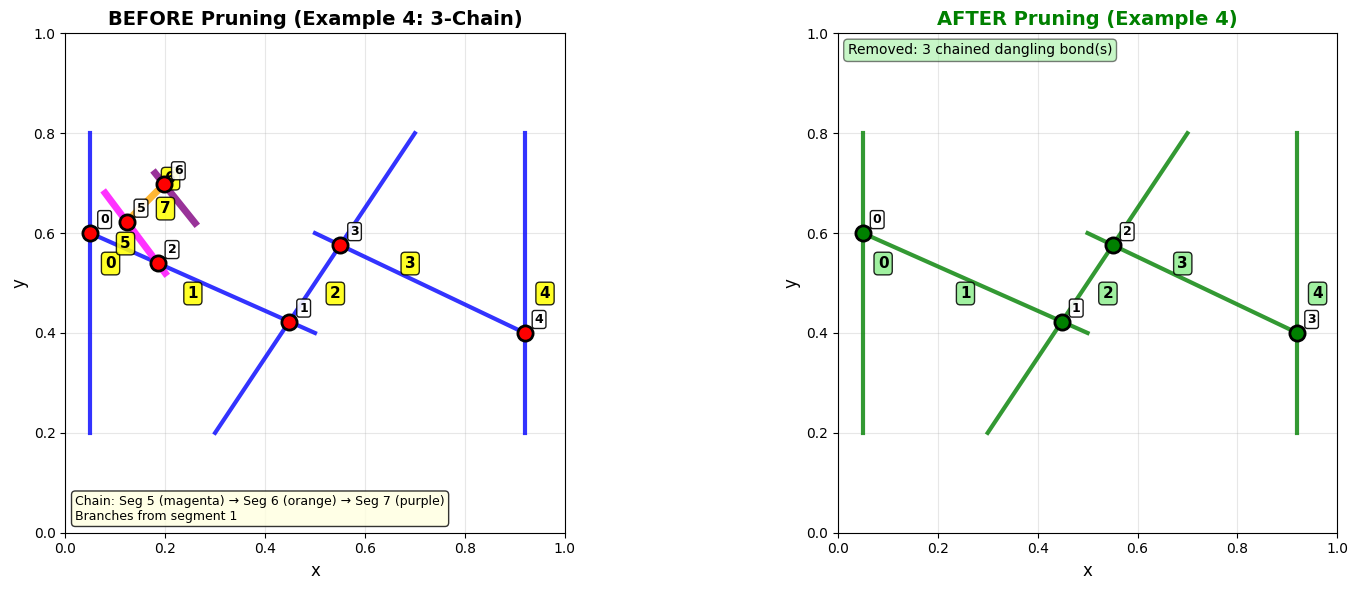

In [ ]:
# EXAMPLE 4: Longer Chain of Dangling Bonds (3 iterations needed)
# Uses the SAME PROVEN main path geometry from Examples 1 and 3
print("\n" + "="*70)
print("EXAMPLE 4: CHAIN OF 3 DANGLING BONDS (3 ITERATIONS)")
print("="*70)

N_ex4 = 8  # 5 main path segments + 3 chained dangling

# USING PROVEN GEOMETRY FROM EXAMPLE 1/3 for the main path!
# Main path: segments 0-4 (identical to Example 1)
# Dangling chain: segment 5 branches off segment 1, then 6 off 5, then 7 off 6

points_1_ex4 = [
    # ===== Main percolating path (0-4) - COPIED FROM EXAMPLE 1 =====
    [0.05, 0.20],   # Segment 0: vertical at source
    [0.05, 0.60],   # Segment 1: diagonal from source through middle
    [0.30, 0.20],   # Segment 2: diagonal crossing middle
    [0.50, 0.60],   # Segment 3: diagonal to drain
    [0.92, 0.20],   # Segment 4: vertical at drain
    # ===== CHAIN of 3 Dangling bonds =====
    [0.20, 0.52],   # Segment 5: branches from segment 1
    [0.12, 0.62],   # Segment 6: branches from segment 5 ONLY
    [0.18, 0.72],   # Segment 7: branches from segment 6 ONLY (dead end)
]

points_2_ex4 = [
    # ===== Main percolating path (0-4) - COPIED FROM EXAMPLE 1 =====
    [0.05, 0.80],   # Segment 0
    [0.50, 0.40],   # Segment 1
    [0.70, 0.80],   # Segment 2
    [0.92, 0.40],   # Segment 3
    [0.92, 0.80],   # Segment 4
    # ===== CHAIN of 3 Dangling bonds =====
    [0.08, 0.68],   # Segment 5: crosses seg 1 AND seg 6
    [0.22, 0.72],   # Segment 6: crosses seg 5 AND seg 7
    [0.26, 0.62],   # Segment 7: ONLY crosses seg 6 (dead end) - goes down-right to intersect seg 6
]

# Calculate angles using the new calculate_angles function
angles_ex4 = calculate_angles(points_1_ex4, points_2_ex4)

# Find intersections
intersections_ex4 = []
intersected_line_1_ex4 = []
intersected_line_2_ex4 = []
graph_ex4 = []

intersections_ex4, intersected_line_1_ex4, intersected_line_2_ex4, graph_ex4 = identify_intersections(
    points_1_ex4, points_2_ex4, intersections_ex4, intersected_line_1_ex4,
    intersected_line_2_ex4, graph_ex4, angles_ex4, 0.7, N_ex4
)

print(f"Intersections found: {len(intersections_ex4)}")
print(f"Graph (segments at each node): {graph_ex4}")

# Verify the chain structure
print("\nVerifying segment connections:")
seg_connections = {}
for segs in graph_ex4:
    for s in segs:
        if s not in seg_connections:
            seg_connections[s] = set()
        for other in segs:
            if other != s:
                seg_connections[s].add(other)
for seg_id in sorted(seg_connections.keys()):
    print(f"  Segment {seg_id} connects to: {sorted(seg_connections[seg_id])}")

# Find boundary nodes
boundary_source_ex4 = []
boundary_drain_ex4 = []
for i in range(len(intersections_ex4)):
    if intersections_ex4[i][0] < 0.1:
        boundary_source_ex4.append(i)
    elif intersections_ex4[i][0] > 0.9:
        boundary_drain_ex4.append(i)

if not boundary_source_ex4 or not boundary_drain_ex4:
    raise ValueError(
        f"Example 4 strict boundary failed: source={len(boundary_source_ex4)}, drain={len(boundary_drain_ex4)}. No fallback allowed."
    )

# Print boundary nodes with coordinates
print("\nBoundary nodes:")
print(f"  Source (x < 0.1): {boundary_source_ex4}")
for node in boundary_source_ex4:
    print(f"    Node {node}: ({intersections_ex4[node][0]:.4f}, {intersections_ex4[node][1]:.4f})")
print(f"  Drain (x > 0.9): {boundary_drain_ex4}")
for node in boundary_drain_ex4:
    print(f"    Node {node}: ({intersections_ex4[node][0]:.4f}, {intersections_ex4[node][1]:.4f})")

# Find paths before pruning
path_nodes_ex4 = []
path_pairs_of_lines_ex4 = []
path_pairs_of_edges_ex4 = []
all_path_perc_ex4 = []
all_path_nodes_ex4 = []

for i in boundary_source_ex4:
    do_not_check = 0
    for k in range(len(all_path_nodes_ex4)):
        if i in all_path_nodes_ex4[k]:
            do_not_check = 1
            break
    if do_not_check == 0:
        nodes, pair_of_lines, pair_of_edges, path_perc = find_path(
            intersections_ex4, graph_ex4, i
        )
        path_nodes_ex4.append(nodes)
        path_pairs_of_lines_ex4.append(pair_of_lines)
        path_pairs_of_edges_ex4.append(pair_of_edges)
        all_path_perc_ex4.append(path_perc)
        all_path_nodes_ex4.append(nodes)

print(f"\nBoundary nodes -> source: {boundary_source_ex4}, drain: {boundary_drain_ex4}")
print(f"Paths found: {len(path_nodes_ex4)}, Percolating: {sum(1 for p in all_path_perc_ex4 if p == 1)}")

# Get boundary segments
source_segments_ex4 = set()
drain_segments_ex4 = set()
for node_idx in boundary_source_ex4:
    if node_idx < len(graph_ex4):
        source_segments_ex4.update(graph_ex4[node_idx])
for node_idx in boundary_drain_ex4:
    if node_idx < len(graph_ex4):
        drain_segments_ex4.update(graph_ex4[node_idx])

print(f"Source segments: {source_segments_ex4}, Drain segments: {drain_segments_ex4}")

# ═══════════════════════════════════════════════════════════════════════
# 🔧 APPLYING PRUNING ALGORITHM - should take 3 iterations
# ═══════════════════════════════════════════════════════════════════════
print("\n" + "="*70)
print(">>> CALLING: prune_dangling_bonds() FROM pruning.py (EXAMPLE 4)")
print(">>> EXPECTING 3 ITERATIONS:")
print(">>>   Iteration 1: Remove segment 7 (only connects to seg 6)")
print(">>>   Iteration 2: Remove segment 6 (now only connects to seg 5)")
print(">>>   Iteration 3: Remove segment 5 (now only connects to seg 2)")
print("="*70)

# Apply pruning
filtered_pair_of_lines_ex4, filtered_path_nodes_ex4, filtered_pair_of_edges_ex4 = prune_dangling_bonds(
    path_pairs_of_lines_ex4, path_nodes_ex4, path_pairs_of_edges_ex4,
    source_segments_ex4, drain_segments_ex4
)

print("="*70)
print(">>> PRUNING COMPLETED (EXAMPLE 4)")
print("="*70)

# Extract remaining segments
segments_after_ex4 = set()
for path in filtered_pair_of_lines_ex4:
    for edge_pair in path:
        segments_after_ex4.update(edge_pair)
segments_after_ex4 = sorted(list(segments_after_ex4))
segments_removed_ex4 = [i for i in range(N_ex4) if i not in segments_after_ex4]

print(f"\nAfter pruning:")
print(f"  Remaining segments: {segments_after_ex4}")
print(f"  Removed segments: {segments_removed_ex4}")
print(f"  Expected: Remove segments 5, 6, AND 7 (the entire chain)")

# Create pruned network
points_1_pruned_ex4 = [points_1_ex4[i] for i in segments_after_ex4]
points_2_pruned_ex4 = [points_2_ex4[i] for i in segments_after_ex4]
N_pruned_ex4 = len(segments_after_ex4)

# Re-analyze pruned network
intersections_pruned_ex4 = []
intersected_line_1_pruned_ex4 = []
intersected_line_2_pruned_ex4 = []
graph_pruned_ex4 = []

if N_pruned_ex4 > 0:
    angles_pruned_ex4 = [angles_ex4[i] for i in segments_after_ex4]
    intersections_pruned_ex4, _, _, graph_pruned_ex4 = identify_intersections(
        points_1_pruned_ex4, points_2_pruned_ex4, intersections_pruned_ex4,
        intersected_line_1_pruned_ex4, intersected_line_2_pruned_ex4, graph_pruned_ex4,
        angles_pruned_ex4, 0.7, N_pruned_ex4
    )

print(f"Intersections after pruning: {len(intersections_pruned_ex4)}")

# Visualize
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Color map for the chain
chain_colors = {5: 'magenta', 6: 'orange', 7: 'purple'}

# Before pruning
for i in range(N_ex4):
    if i <= 4:
        color = 'blue'
        linewidth = 3
    else:
        color = chain_colors.get(i, 'red')
        linewidth = 5
    ax1.plot([points_1_ex4[i][0], points_2_ex4[i][0]],
             [points_1_ex4[i][1], points_2_ex4[i][1]],
             linestyle='-', color=color, linewidth=linewidth, alpha=0.8)
    mid_x = (points_1_ex4[i][0] + points_2_ex4[i][0]) / 2
    mid_y = (points_1_ex4[i][1] + points_2_ex4[i][1]) / 2
    offset_x = 0.03 if i % 2 == 0 else -0.03
    offset_y = 0.03 if i % 3 == 0 else -0.03
    ax1.text(mid_x + offset_x, mid_y + offset_y, str(i), fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='yellow', alpha=0.85))

# Plot intersections
if len(intersections_ex4) > 0:
    for node_id, (x, y) in enumerate(intersections_ex4):
        ax1.scatter(x, y, c='red', marker='o', s=120, zorder=5, edgecolors='black', linewidths=2)
        ax1.text(x + 0.02, y + 0.02, str(node_id), fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

ax1.set_title("BEFORE Pruning (Example 4: 3-Chain)", fontsize=14, fontweight='bold')
ax1.set_xlabel("x", fontsize=12)
ax1.set_ylabel("y", fontsize=12)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.set_aspect('equal')
ax1.grid(True, alpha=0.3)
ax1.text(0.02, 0.02, 'Chain: Seg 5 (magenta) → Seg 6 (orange) → Seg 7 (purple)\nBranches from segment 1',
         transform=ax1.transAxes, fontsize=9, verticalalignment='bottom',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

# After pruning
for i, orig_idx in enumerate(segments_after_ex4):
    ax2.plot([points_1_pruned_ex4[i][0], points_2_pruned_ex4[i][0]],
             [points_1_pruned_ex4[i][1], points_2_pruned_ex4[i][1]],
             linestyle='-', color='green', linewidth=3, alpha=0.8)
    mid_x = (points_1_pruned_ex4[i][0] + points_2_pruned_ex4[i][0]) / 2
    mid_y = (points_1_pruned_ex4[i][1] + points_2_pruned_ex4[i][1]) / 2
    offset_x = 0.03 if i % 2 == 0 else -0.03
    offset_y = 0.03 if i % 3 == 0 else -0.03
    ax2.text(mid_x + offset_x, mid_y + offset_y, str(orig_idx), fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='lightgreen', alpha=0.85))

if len(intersections_pruned_ex4) > 0:
    for node_id, (x, y) in enumerate(intersections_pruned_ex4):
        ax2.scatter(x, y, c='green', marker='o', s=120, zorder=5, edgecolors='black', linewidths=2)
        ax2.text(x + 0.02, y + 0.02, str(node_id), fontsize=9, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))

ax2.set_title("AFTER Pruning (Example 4)", fontsize=14, fontweight='bold', color='green')
ax2.set_xlabel("x", fontsize=12)
ax2.set_ylabel("y", fontsize=12)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.set_aspect('equal')
ax2.grid(True, alpha=0.3)
ax2.text(0.02, 0.98, f'Removed: {len(segments_removed_ex4)} chained dangling bond(s)',
         transform=ax2.transAxes, fontsize=10, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

plt.tight_layout()
plt.show()

print("="*70)